# Choosing a Neural Network: CNN vs. RNN vs. Transformer

Same training loop, three architectures. Which one fits the data, and what does it cost?

**Goals:** read the PyTorch pipeline (`Tensor → Dataset → DataLoader → nn.Module → loss → backward → optimizer`), match an architecture to the data, and judge models by accuracy **and** compute.

**Plan:** for each dataset we build, train, and inspect one model at a time (CNN → RNN → Transformer), then compare all three.
- **A. MNIST digits:** is a small CNN enough?
- **B. Delayed recall:** which models can carry information across time?
- **C. Scaling:** how do time and memory grow with input length?

**Run it yourself:** `pip install torch numpy pandas matplotlib`, then run the cells in order (Apple MPS, NVIDIA CUDA, Colab, or CPU).

## 1. Setup
### 1.1 Environment and settings
PyTorch picks the fastest device. A model and its data must be on the **same** device.

In [ ]:
import time, gzip, hashlib, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.utils.flop_counter import FlopCounterMode
from torch.nn.attention import sdpa_kernel, SDPBackend
from IPython.display import display

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

# ---- Experiment settings (change one at a time, then rerun from the top) ----
SEED = 42

# Examples per gradient update, shared by all models.
# Larger batches use the GPU better (fewer, bigger steps per epoch) but need more memory
# (activations grow linearly with the batch size) and give fewer updates per epoch.
# Smaller batches give noisier gradients and slower epochs. 128 is a common middle ground.
BATCH_SIZE = 128

# Optimizer settings, shared by all models (used by train_model in section 3.2).
# AdamW adapts the step size for every weight, so one setting works for all three models.
# 2e-3 is a bit above the usual 1e-3 default because these models are small and train
# for only a few epochs. Too high (e.g. 1e-2): the loss jumps around or turns into NaN.
# Too low (e.g. 1e-4): learning is slow.
LEARNING_RATE = 2e-3
# Weight decay gently pulls weights toward zero, which discourages overfitting.
# Larger values can make the model underfit; 0 turns it off.
WEIGHT_DECAY = 1e-4

# MNIST: hold out 5,000 training images for validation (one image = 0.02% accuracy, so the
# estimate is stable). 3 epochs: the CNN is near its best after one; extra epochs mostly
# help the slower-learning models (see the exercises).
IMAGE_VAL = 5_000
IMAGE_EPOCHS = 3

# Copying Memory: remember K symbols, wait DELAY steps, then repeat them.
# A longer DELAY is harder for the RNN (it must remember longer) and makes attention more
# expensive (longer inputs). K=3 keeps the number of possible triples small (8^3 = 512).
MEMORY_K, DELAY = 3, 16
# Sequence length: K symbols + (DELAY - 1) waits + (K + 1) recall markers = 22
SEQ_LEN = DELAY + 2 * MEMORY_K
MEMORY_TRAIN, MEMORY_VAL, MEMORY_TEST = 4096, 512, 512
# The Transformer needs about 6 epochs to reach 100%; 8 leaves some margin.
MEMORY_EPOCHS = 8

# MNIST files are cached here
DATA_DIR = Path('pytorch_demo_data')
# Plots, CSVs, and checkpoints go here
RESULT_DIR = Path('pytorch_demo_results')
DATA_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

# Fastest device first: NVIDIA GPU > Apple GPU > CPU.
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

def seed_everything(seed=SEED):
    """Fix the random number generators so reruns give (nearly) the same numbers."""
    np.random.seed(seed)
    # Seeds the CPU generator and the CUDA / MPS ones
    torch.manual_seed(seed)

def synchronize():
    """GPUs run asynchronously. Wait for queued work to finish before reading a timer."""
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()

seed_everything()
print(f'PyTorch {torch.__version__} | device: {device}')

### 1.2 Tensors and gradients
A **tensor** is an n-dimensional array with a shape, dtype, and device. Images are `[B, C, H, W]`, sequences `[B, L, D]` (B = batch size).

**Autograd** computes how the loss changes with each parameter. For loss $=(wx-4)^2$ with $x=2,\ w=3$: $\frac{d\,\text{loss}}{dw} = 2(wx-4)\,x = 8$.

In [ ]:
# A batch of 4 grayscale 28x28 images: [B, C, H, W]
images = torch.zeros(4, 1, 28, 28)
# Drop the channel axis -> [B, 28, 28]: a sequence of 28 rows with 28 pixels each.
# (This is how the RNN will read an image later.)
rows = images.squeeze(1)
print('images:', tuple(images.shape), '-> rows as a sequence:', tuple(rows.shape))

# requires_grad=True tells PyTorch to record every operation on w.
w = torch.tensor(3.0, requires_grad=True, device=device)
# Forward pass: (3*2 - 4)^2 = 4
loss = (w * 2.0 - 4.0) ** 2
# Backward pass: fills in w.grad
loss.backward()
# Expect dloss/dw = 8
print('loss =', loss.item(), '| dloss/dw =', w.grad.item())

### 1.3 Helper functions
Tools that measure each model's cost and draw its results. Run this cell; you don't need to read it now.

In [ ]:
# ---- Measuring cost ----
def count_params(model):
    """Number of trainable numbers (weights and biases) in a model."""
    return sum(p.numel() for p in model.parameters())

def allocated_mb():
    """Memory currently held by tensors on the GPU (not tracked on CPU)."""
    if device.type == 'cuda':
        return torch.cuda.memory_allocated() / 2**20
    if device.type == 'mps':
        return torch.mps.current_allocated_memory() / 2**20
    return float('nan')

def free_gpu_cache():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()

def activation_memory_mb(model, x):
    """GPU memory that one forward pass keeps around for the backward pass."""
    model.train()
    synchronize()
    before = allocated_mb()
    # With gradients on, every layer saves its inputs for the backward pass
    out = model(x)
    used = allocated_mb() - before
    # Frees those activations again
    del out
    return used

def mflops_per_example(Model, x, y):
    """Count the arithmetic of one forward + backward pass (on CPU), per example."""
    model = Model()
    # The MATH attention backend uses plain matmuls, so the counter sees all of them.
    with sdpa_kernel(SDPBackend.MATH), FlopCounterMode(display=False) as counter:
        logits = model(x)
        F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1)).backward()
    return counter.get_total_flops() / len(x) / 1e6


# ---- Showing results ----
palette = {'CNN': '#782f40', 'RNN (GRU)': '#477b75', 'Transformer': '#c79b45',
           'Dilated CNN': '#8e6c9e'}

@torch.no_grad()
def predict(model, x, chunk=1000):
    """Predicted class for every example in x (computed on the GPU in chunks)."""
    model.eval().to(device)
    preds = [model(x[i:i + chunk].to(device)).argmax(dim=-1).cpu() for i in range(0, len(x), chunk)]
    model.cpu()
    return torch.cat(preds)

def show_results(task, name):
    """Print one model's scores and costs, plot its learning curve, and show test predictions."""
    row, model = RESULTS[(task, name)], TRAINED[(task, name)]
    curve = pd.DataFrame(HISTORIES[(task, name)])
    exact = f" | all 3 symbols right: {row['test_exact_acc']:.1%}" if task == 'Memory' else ''
    print(f"Test accuracy: {row['test_acc']:.1%}{exact}")
    print(f"Size: {row['params']:,} parameters | compute: {row['mflops']:.1f} MFLOPs per example"
          f" | GPU memory: {row['train_mem_mb']:.1f} MB per batch")
    print(f"Speed: {row['s_per_epoch']:.2f} s per training epoch"
          f" | {row['infer_per_s']:,.0f} examples/s at inference")

    if task == 'MNIST':
        fig = plt.figure(figsize=(11, 2.8))
        grid = fig.add_gridspec(2, 6, wspace=0.3)
        ax = fig.add_subplot(grid[:, :2])
        # Right side: some test digits this model gets wrong.
        xs, ys = image_sets['test'].tensors
        preds = predict(model, xs)
        wrong = torch.where(preds != ys)[0]
        for k, i in enumerate(wrong[:8]):
            sub = fig.add_subplot(grid[k // 4, 2 + k % 4])
            sub.imshow(xs[i, 0] * IMAGE_STD + IMAGE_MEAN, cmap='gray')
            sub.set_title(f'true {ys[i]} / pred {preds[i]}', fontsize=8, color='#ad3131')
            sub.axis('off')
        fig.text(0.68, 1.0, f'{len(wrong)} of {len(ys):,} test digits wrong, for example:',
                 ha='center', fontsize=9)
        ref, low = 95, min(curve.val_acc.min() * 100, 95) - 3
    else:
        fig, ax = plt.subplots(figsize=(4.5, 2.8))
        ref, low = 100 / 8, 0
    # Left side: validation accuracy after each epoch (dotted: 95% target / chance level).
    ax.plot(curve.epoch, curve.val_acc * 100, marker='o', color=palette[name])
    ax.axhline(ref, ls=':', color='gray')
    ax.set(title=f'{name}: validation accuracy', xlabel='Epoch', ylabel='%',
           xticks=curve.epoch, ylim=(low, 101))
    plt.show()

    if task == 'Memory':
        # Its answers for 6 unseen test sequences.
        xs, ys = memory_sets['test'].tensors
        preds = predict(model, xs[:6]) + 1
        targets = ys[:6] + 1
        display(pd.DataFrame({'target': targets.tolist(), 'prediction': preds.tolist(),
                              'correct': ['✓' if p.equal(t) else '✗' for p, t in zip(preds, targets)]}))

def bar_panel(ax, models, values, title, fmt, bottom=None):
    """One bar per model, labeled with its value and its ratio to the CNN (the first bar)."""
    colors = [palette[m] for m in models]
    if bottom is None:
        bars = ax.bar(models, values, color=colors)
    else:
        # Stacked bars: dark part = `bottom`, light part = the rest
        ax.bar(models, bottom, color=colors)
        bars = ax.bar(models, values - bottom, bottom=bottom, color=colors, alpha=0.45)
    for bar, v in zip(bars, values):
        top = bar.get_y() + bar.get_height()
        label = f'{fmt(v)}\n({v / values[0]:.1f}× CNN)' if np.isfinite(v) else 'n/a on CPU'
        ax.text(bar.get_x() + bar.get_width() / 2, np.nan_to_num(top), label,
                ha='center', va='bottom', fontsize=8)
    ax.set_title(title, fontsize=10)
    # Two-line tick labels ("RNN" / "(GRU)") so they don't collide in narrow panels
    ax.set_xticks(range(len(models)), [m.replace(' (', '\n(') for m in models], fontsize=8)
    # The bar labels already give the values
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    # Leave room for the labels
    ax.margins(y=0.35)

def compare_models(task):
    """Table, learning curves, and cost bars for the CNN, RNN, and Transformer of one task."""
    names = [n for n in ['CNN', 'RNN (GRU)', 'Transformer'] if (task, n) in RESULTS]
    r = pd.DataFrame([RESULTS[(task, n)] for n in names])
    curves = pd.DataFrame([h for n in names for h in HISTORIES[(task, n)]])
    r['x_cnn_time'] = r.s_per_epoch / r.s_per_epoch.iloc[0]
    # "Fast" can also mean: training seconds until validation accuracy first reaches 95%
    r['s_to_95'] = [next((h['cumulative_s'] for h in HISTORIES[(task, n)] if h['val_acc'] >= 0.95),
                         np.nan) for n in names]

    columns = {'model': 'model', 'params': 'params', 's_per_epoch': 'sec / epoch',
               'x_cnn_time': '× CNN time', 's_to_95': 'sec to 95% val', 'test_acc': 'test acc'}
    if task == 'Memory':
        columns['test_exact_acc'] = 'all 3 right'
    formats = {'params': '{:,}', 'sec / epoch': '{:.2f}', '× CNN time': '{:.1f}×',
               'sec to 95% val': '{:.1f}', 'test acc': '{:.1%}', 'all 3 right': '{:.1%}'}
    table = r[list(columns)].rename(columns=columns)
    display(table.style.format({c: f for c, f in formats.items() if c in table},
                               na_rep='never').hide(axis='index'))

    fig = plt.figure(figsize=(16, 7.5))
    grid = fig.add_gridspec(2, 10, height_ratios=[1.1, 1], hspace=0.5, wspace=0.8)
    # Top row: learning curves per epoch and per second of training.
    acc_epoch, acc_time = fig.add_subplot(grid[0, :5]), fig.add_subplot(grid[0, 5:])
    ref = 95 if task == 'MNIST' else 100 / 8
    low = min(curves.val_acc.min() * 100, ref) - 3 if task == 'MNIST' else 0
    for name in names:
        c = curves[curves.model == name]
        style = dict(marker='o', color=palette[name], label=name)
        acc_epoch.plot(c.epoch, c.val_acc * 100, **style)
        acc_time.plot(c.cumulative_s, c.val_acc * 100, **style)
    for ax in (acc_epoch, acc_time):
        ax.axhline(ref, ls=':', color='gray')
        ax.set(ylim=(low, 101), ylabel='Validation accuracy (%)')
    acc_epoch.set(title='Accuracy per epoch', xlabel='Epoch', xticks=range(1, curves.epoch.max() + 1))
    acc_time.set(title='Accuracy vs. training time (further left = faster)', xlabel='Training time (s)')
    acc_epoch.legend(loc='lower right' if task == 'MNIST' else 'center right', fontsize=8)

    # Bottom row: five cost measures.
    panels = [('Parameters', r.params.values, lambda v: f'{v / 1e3:.0f}k', None),
              ('MFLOPs per example', r.mflops.values, lambda v: f'{v:.1f}M', None),
              ('GPU memory (MB)', r.train_mem_mb.values, lambda v: f'{v:.1f} MB', r.weights_mb.values),
              ('Training s / epoch', r.s_per_epoch.values, lambda v: f'{v:.2f} s', None),
              ('Inference examples / s', r.infer_per_s.values, lambda v: f'{v / 1e3:.0f}k/s', None)]
    for k, (title, values, fmt, bottom) in enumerate(panels):
        ax = fig.add_subplot(grid[1, 2 * k:2 * k + 2])
        bar_panel(ax, names, values, title, fmt, bottom)
        if bottom is not None:
            ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='gray'),
                               plt.Rectangle((0, 0), 1, 1, color='gray', alpha=0.45)],
                      labels=['weights + grads + optimizer', 'activations'],
                      loc='upper left', fontsize=7, frameon=False)
    fig.suptitle(f'{task}: CNN vs. RNN (GRU) vs. Transformer', fontsize=13)
    fig.savefig(RESULT_DIR / f'{task.lower()}_comparison.png', bbox_inches='tight')
    plt.show()

## 2. Dataset A: MNIST handwritten digits
70,000 grayscale 28×28 digit images, split three ways: **train** (55,000) to learn the weights, **validation** (5,000) to pick the best epoch, and **test** (10,000) for one final score.

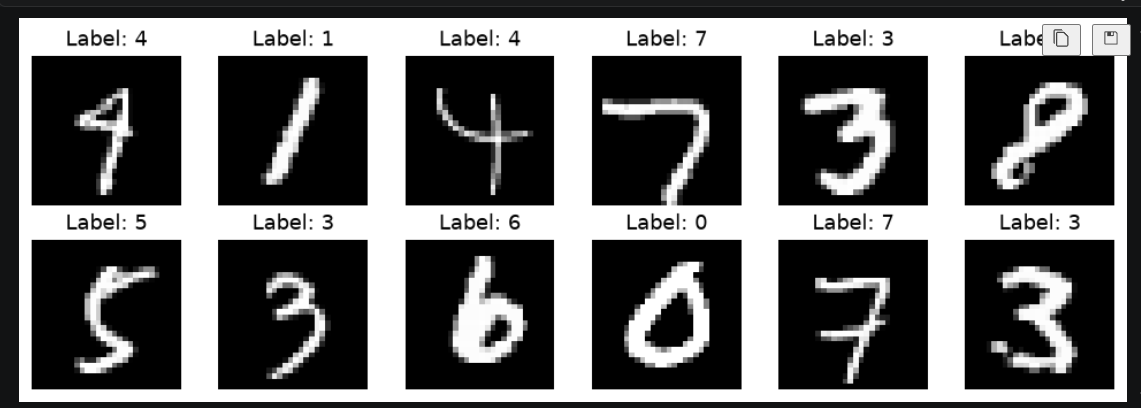

In [ ]:
# Official MNIST files and their MD5 checksums (same mirrors torchvision uses).
MNIST_FILES = {
    'train-images-idx3-ubyte.gz': 'f68b3c2dcbeaaa9fbdd348bbdeb94873',
    'train-labels-idx1-ubyte.gz': 'd53e105ee54ea40749a09fcbcd1e9432',
    't10k-images-idx3-ubyte.gz':  '9fb629c4189551a2d022fa330f9573f3',
    't10k-labels-idx1-ubyte.gz':  'ec29112dd5afa0611ce80d1b7f02629c',
}
MIRRORS = ['https://ossci-datasets.s3.amazonaws.com/mnist/',
           'https://storage.googleapis.com/cvdf-datasets/mnist/']

def download(name):
    """Return the local path of an MNIST file, downloading it the first time."""
    path = DATA_DIR / name
    if path.exists() and hashlib.md5(path.read_bytes()).hexdigest() == MNIST_FILES[name]:
        # Already cached and intact
        return path
    # Otherwise, try each mirror until one works
    for base in MIRRORS:
        try:
            with urllib.request.urlopen(base + name, timeout=45) as response:
                content = response.read()
            # Keep the file only if its checksum matches (rejects corrupt downloads)
            if hashlib.md5(content).hexdigest() == MNIST_FILES[name]:
                path.write_bytes(content)
                print('Downloaded', name)
                return path
        except OSError:
            pass
    raise RuntimeError(f'Could not download {name}. Check your internet connection.')

def read_idx(name):
    """Parse MNIST's IDX format: a small header with the shape, then raw uint8 values."""
    raw = gzip.decompress(download(name).read_bytes())
    # Byte 3 of the header = number of dimensions
    ndim = raw[3]
    # Then one big-endian 4-byte size per dimension
    shape = np.frombuffer(raw, dtype='>u4', count=ndim, offset=4)
    data = np.frombuffer(raw, dtype=np.uint8, offset=4 + 4 * ndim)
    return torch.from_numpy(data.copy().reshape(tuple(shape)))

# [60000, 28, 28] uint8 pixel values 0-255
train_images = read_idx('train-images-idx3-ubyte.gz')
# [60000] class ids 0-9
train_labels = read_idx('train-labels-idx1-ubyte.gz').long()
# [10000, 28, 28] and [10000]
test_images = read_idx('t10k-images-idx3-ubyte.gz')
test_labels = read_idx('t10k-labels-idx1-ubyte.gz').long()

# Shuffle once with a fixed seed, then hold out the first 5,000 images for validation.
perm = torch.randperm(len(train_images), generator=torch.Generator().manual_seed(SEED))
val_idx, train_idx = perm[:IMAGE_VAL], perm[IMAGE_VAL:]

# Normalize to mean 0 / std 1 using TRAINING statistics only (never peek at val/test).
# Inputs centered around 0 make the first layer's job easier and training more stable.
pixels = train_images[train_idx].float() / 255.0
IMAGE_MEAN, IMAGE_STD = pixels.mean().item(), pixels.std().item()
del pixels

def image_dataset(images, labels):
    """uint8 [N, 28, 28] -> normalized float [N, 1, 28, 28], paired with labels."""
    x = (images.float().unsqueeze(1) / 255.0 - IMAGE_MEAN) / IMAGE_STD
    return TensorDataset(x, labels)

image_sets = {
    'train': image_dataset(train_images[train_idx], train_labels[train_idx]),
    'val':   image_dataset(train_images[val_idx],   train_labels[val_idx]),
    'test':  image_dataset(test_images,             test_labels),
}
print({split: len(ds) for split, ds in image_sets.items()})

## 3. CNN on MNIST
### 3.1 Build the CNN
A CNN slides small filters over the image. The same filter is reused at every position, so a stroke detector learned in one corner works everywhere. **Built-in assumption:** nearby pixels belong together.

In [ ]:
class ImageCNN(nn.Module):
    """Two convolution blocks extract local features; a small MLP turns them into 10 digit scores."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 1 input channel (grayscale) -> 16 feature maps.
            # kernel_size=3: a 3x3 window is the smallest that can detect an edge in any
            #   direction. kernel_size=5 sees more per layer but costs 25/9 ≈ 2.8x the weights
            #   and FLOPs. (In general, two stacked 3x3 convs see a 5x5 area with 18 instead
            #   of 25 weights per channel pair.)
            # padding=1: adds a 1-pixel border so the output stays 28x28 and edge pixels count
            #   fully. With padding=0, each conv shrinks the map by 2 pixels (28 -> 26).
            # 16 filters: enough to learn basic strokes. More filters = more capacity, but also
            #   more FLOPs and more activation memory.
            # Shape: [B, 1, 28, 28] -> [B, 16, 28, 28]
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            # ReLU keeps positive values and zeroes the rest. Without a non-linearity,
            # stacked layers would collapse into one linear function.
            nn.ReLU(),
            # 2x2 max pooling keeps the strongest response in each 2x2 window. It halves
            # height and width (4x fewer positions, so the next layer is 4x cheaper) and makes
            # the features tolerant to small shifts of the digit.
            # Shape: -> [B, 16, 14, 14]
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 16 -> 32 feature maps. Doubling the channels while halving the
            # resolution is a common pattern: deeper layers combine simple strokes into more
            # (and more complex) shapes, at a similar cost per layer.
            # Shape: -> [B, 32, 14, 14], then pooled to [B, 32, 7, 7]
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        # After the two blocks, each of the 7x7 positions "sees" a 10x10-pixel patch of the
        # input (its receptive field): big enough for a piece of a digit.
        self.classifier = nn.Sequential(
            # Flatten the 32 maps of 7x7 into one vector of 32*7*7 = 1,568 numbers per image.
            nn.Flatten(),
            # Hidden layer with 32 units. This one layer holds 1,568*32 + 32 = 50,208 weights,
            # about 90% of the whole model! Fewer units = smaller model but less capacity;
            # more units = more capacity and a higher risk of overfitting.
            nn.Linear(32 * 7 * 7, 32),
            nn.ReLU(),
            # Output layer: one score (logit) per digit class 0-9.
            nn.Linear(32, 10),
        )

    def forward(self, x):
        # Input x: [B, 1, 28, 28] normalized images. Output: [B, 10] logits.
        return self.classifier(self.features(x))


# Quick check on a fake batch of 2 images: output shape and model size.
model = ImageCNN()
print('output:', tuple(model(torch.zeros(2, 1, 28, 28)).shape), '| parameters:', f'{count_params(model):,}')

### 3.2 Train the CNN
Every model in this notebook uses the same training loop. Each update has five steps: **① zero gradients → ② forward → ③ loss → ④ backward → ⑤ optimizer step.** One **epoch** = one pass over the training set. After each epoch we check validation accuracy and keep the best weights.

In [ ]:
# Every trained model, its summary row, and its per-epoch history, keyed by (task, model name).
# Dictionaries make reruns safe: training a model again simply replaces its old entry.
TRAINED, RESULTS, HISTORIES = {}, {}, {}

def make_loaders(datasets):
    """Reshuffle the training set every epoch; keep validation/test in a fixed order."""
    # A fixed generator gives every model the same batch order, which keeps the comparison fair.
    g = torch.Generator().manual_seed(SEED)
    return {split: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == 'train'), generator=g)
            for split, ds in datasets.items()}

def loss_fn(logits, y):
    """Cross-entropy loss. It applies softmax internally, so models output raw logits.
    For the recall task, the 3 output positions are folded into the batch:
    [B, 3, 8] vs. [B, 3] -> [3B, 8] vs. [3B]. MNIST's [B, 10] vs. [B] is unchanged."""
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1))

# Evaluation needs no gradients (faster, less memory)
@torch.no_grad()
def evaluate(model, loader):
    """Accuracy per prediction, plus the share of examples with ALL predictions right."""
    # eval() switches layers like dropout to inference behavior
    model.eval()
    correct = total = exact = n_examples = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        # The predicted class is the one with the highest logit
        hits = model(x).argmax(dim=-1).eq(y)
        correct += hits.sum().item()
        total += y.numel()
        # Recall task: a sequence counts only if all 3 symbols are right (MNIST: same as accuracy)
        exact += hits.reshape(len(y), -1).all(dim=1).sum().item()
        n_examples += len(y)
    return dict(acc=correct / total, exact_acc=exact / n_examples)

def train_model(task, name, Model, datasets, epochs):
    """Train a fresh model, keep its best epoch (by validation accuracy), and measure its cost."""
    # Same seed for every model: same kind of random start, same batch order
    seed_everything()
    model = Model().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loaders = make_loaders(datasets)

    # Warm-up: one untimed forward + backward pass, so one-time GPU setup isn't counted as
    # training time. There is no optimizer step, so the weights don't change.
    probe_x, probe_y = next(iter(loaders['train']))
    loss_fn(model(probe_x.to(device)), probe_y.to(device)).backward()
    model.zero_grad()

    best_acc, best_state, history = -1.0, None, []
    train_time, eval_time = 0.0, 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        synchronize()
        start = time.perf_counter()
        for x, y in loaders['train']:
            # Move the batch to the same device as the model
            x, y = x.to(device), y.to(device)
            # ① Clear the gradients from the previous step (PyTorch would add them up otherwise)
            optimizer.zero_grad()
            # ② Forward pass: compute the logits
            logits = model(x)
            # ③ Loss: one number that measures how wrong the logits are
            loss = loss_fn(logits, y)
            # ④ Backward pass: compute the gradient of the loss for every weight
            loss.backward()
            # (Cap the overall gradient size at 1.0, so one unusually large step can't wreck
            #  training. This matters most for RNNs; a smaller cap makes training more cautious.)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            # ⑤ Update every weight a small step against its gradient
            optimizer.step()
        # GPU work is queued asynchronously: wait for it to finish, then stop the clock
        synchronize()
        epoch_time = time.perf_counter() - start
        train_time += epoch_time

        # Validation (timed separately: this gives the inference speed)
        start = time.perf_counter()
        val = evaluate(model, loaders['val'])
        eval_time += time.perf_counter() - start
        history.append(dict(task=task, model=name, epoch=epoch, val_acc=val['acc'],
                            epoch_s=epoch_time, cumulative_s=train_time))
        print(f'  epoch {epoch}/{epochs}: val acc {val["acc"]:6.1%} | {epoch_time:5.2f} s')
        # Keep a copy of the best weights so far
        if val['acc'] > best_acc:
            best_acc = val['acc']
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    # Roll back to the best epoch, then score it ONCE on the test set
    model.load_state_dict(best_state)
    test = evaluate(model, loaders['test'])

    # Cost of one training batch: weights + gradients + 2 AdamW buffers (4 copies of every
    # parameter, 4 bytes each), plus the activations saved during the forward pass.
    n_params = count_params(model)
    weights_mb = 4 * 4 * n_params / 2**20
    activation_mb = activation_memory_mb(model, probe_x.to(device))
    RESULTS[(task, name)] = dict(
        task=task, model=name, params=n_params, s_per_epoch=train_time / epochs,
        train_s=train_time, val_acc=best_acc, test_acc=test['acc'], test_exact_acc=test['exact_acc'],
        # Inference speed in examples per second
        infer_per_s=len(datasets['val']) * epochs / eval_time,
        weights_mb=weights_mb, activation_mb=activation_mb, train_mem_mb=weights_mb + activation_mb,
        mflops=mflops_per_example(Model, probe_x[:8], probe_y[:8]))
    HISTORIES[(task, name)] = history
    # Keep the trained model on the CPU to free GPU memory for the next one
    TRAINED[(task, name)] = model.cpu()
    free_gpu_cache()

**Predict:** how accurate will the CNN be after a single pass over the data?

In [ ]:
# About 7 s on an Apple M4 Pro
train_model('MNIST', 'CNN', ImageCNN, image_sets, epochs=IMAGE_EPOCHS)

### 3.3 CNN results
Note the accuracy after the first epoch and the cost line. Many of the wrong digits are hard to read even for people.

In [ ]:
show_results('MNIST', 'CNN')

## 4. RNN (GRU) on MNIST
### 4.1 Build the RNN
An RNN reads its input one step at a time and updates a memory vector (the **hidden state**). We feed the image row by row: 28 steps of 28 pixels. A **GRU** adds gates that decide what to keep and what to overwrite. **Built-in assumption:** the input is an ordered sequence.

In [ ]:
class ImageGRU(nn.Module):
    """Reads the image top to bottom, one row per step, then classifies its final memory."""
    def __init__(self):
        super().__init__()
        # input_size=28: each time step receives one image row (28 pixels). This also fixes
        #   the sequence at 28 steps, and they run one after another: the GPU can't start row 20
        #   before row 19 is done. That is why the GRU is slow despite needing few FLOPs.
        # hidden_size=64: the size of the memory vector carried from row to row. The recurrent
        #   weights grow with hidden_size^2 (3 gates x 64 x 64): hidden_size=128 would mean
        #   about 3.4x the parameters and FLOPs, and more room to remember details.
        # num_layers=1: a second stacked GRU layer adds capacity but doubles the sequential work.
        # batch_first=True: inputs are [B, steps, features] (PyTorch's default is [steps, B, features]).
        # Why a GRU instead of a plain nn.RNN? Its gates let gradients flow across many steps,
        # so it trains reliably on 28 rows. An LSTM works similarly with 4 gates instead of 3.
        self.gru = nn.GRU(input_size=28, hidden_size=64, num_layers=1, batch_first=True)
        # Classifier: 64 memory values -> 10 digit scores
        self.classifier = nn.Linear(64, 10)

    def forward(self, x):
        # [B, 1, 28, 28] -> [B, 28, 28]: drop the channel axis, giving 28 steps of 28 pixels
        rows = x.squeeze(1)
        # h_last: [num_layers, B, 64], the memory after reading the last row. It must summarize
        # the whole image, because the classifier sees nothing else.
        _, h_last = self.gru(rows)
        # [B, 64] -> [B, 10] logits
        return self.classifier(h_last[-1])


# Quick check on a fake batch of 2 images: output shape and model size.
model = ImageGRU()
print('output:', tuple(model(torch.zeros(2, 1, 28, 28)).shape), '| parameters:', f'{count_params(model):,}')

### 4.2 Train the RNN
Same `train_model` as before; only the model class changes.

**Predict:** the GRU has about 3× fewer parameters than the CNN. Will it train faster?

In [ ]:
# About 20 s on an Apple M4 Pro
train_model('MNIST', 'RNN (GRU)', ImageGRU, image_sets, epochs=IMAGE_EPOCHS)

### 4.3 RNN results
Compare with the CNN: fewer parameters and FLOPs, yet slower per epoch. Why? (Hint: 28 steps, one after another.)

In [ ]:
show_results('MNIST', 'RNN (GRU)')

## 5. Transformer on MNIST
### 5.1 Build the Transformer
A Vision Transformer (ViT) cuts the image into patches (**tokens**). In every layer, each token **attends** to all other tokens and decides which ones matter. **Built-in assumption:** almost none; it has to learn from data that nearby pixels matter.

In [ ]:
def transformer_encoder(width, layers, heads=4):
    """A stack of standard Transformer blocks (self-attention + small MLP). Reused later."""
    block = nn.TransformerEncoderLayer(
        # d_model: length of each token vector. It must be divisible by the number of heads.
        d_model=width,
        # nhead: number of attention "heads". Each head (width / heads dims) learns its own
        #   pattern of which tokens to look at. More heads = more patterns, each narrower;
        #   the cost stays about the same.
        nhead=heads,
        # dim_feedforward: hidden size of the MLP inside each block. The original Transformer
        #   and ViT use 4x width; 2x keeps the model small and fast.
        dim_feedforward=2 * width,
        # dropout=0: we train only a few epochs on plenty of data, so there is little
        #   overfitting to fight and dropout would slow learning. Long runs typically use 0.1.
        dropout=0.0,
        # Inputs are [B, tokens, width]
        batch_first=True,
        # Pre-norm (normalize before each sub-layer): more stable to train than the original
        #   post-norm, especially without a learning-rate warm-up.
        norm_first=True)
    # nn.TransformerEncoder stacks `layers` copies of the block
    return nn.TransformerEncoder(block, num_layers=layers, enable_nested_tensor=False)


class ImageTransformer(nn.Module):
    """A tiny Vision Transformer: patches -> tokens -> attention layers -> class scores."""
    def __init__(self, width=64, layers=4, patch=4):
        super().__init__()
        # patch=4: cut the 28x28 image into 7x7 = 49 patches of 4x4 pixels (patch must divide 28).
        #   The number of tokens drives the cost, because attention compares every pair:
        #   patch=2 -> 196 tokens -> 16x more attention work per layer (about 3x slower overall);
        #   patch=7 -> 16 tokens -> much cheaper, but each token is a coarse 7x7 blob.
        n_tokens = (28 // patch) ** 2
        # Patch embedding: a conv whose stride equals its kernel size looks at each patch
        #   exactly once and turns its 4x4 pixels into one token vector of length `width`.
        self.patchify = nn.Conv2d(1, width, kernel_size=patch, stride=patch)
        # Position embedding: attention by itself ignores order (it sees a "bag of patches").
        #   A learned vector per position tells the model where each patch came from.
        #   It starts small (x 0.02), as a gentle hint rather than noise.
        self.position = nn.Parameter(torch.randn(1, n_tokens, width) * 0.02)
        # width=64, layers=4: each layer adds about 33k parameters. A larger width or more layers
        #   give more capacity but cost more FLOPs, memory, and time. Even so, this is already
        #   the largest of the three models.
        self.encoder = transformer_encoder(width, layers)
        self.classifier = nn.Linear(width, 10)

    def forward(self, x):
        # [B, 1, 28, 28] -> [B, 64, 7, 7]: one 64-d vector per 4x4 patch
        tokens = self.patchify(x)
        # -> [B, 49, 64]: a sequence of 49 tokens
        tokens = tokens.flatten(2).transpose(1, 2)
        # In each of the 4 layers, every token attends to all 49 tokens
        encoded = self.encoder(tokens + self.position)
        # Average the 49 tokens into one summary of the image (ViT often uses a special [CLS]
        # token instead; averaging is simpler) -> [B, 10] logits
        return self.classifier(encoded.mean(dim=1))


# Quick check on a fake batch of 2 images: output shape and model size.
model = ImageTransformer()
print('output:', tuple(model(torch.zeros(2, 1, 28, 28)).shape), '| parameters:', f'{count_params(model):,}')

### 5.2 Train the Transformer
**Predict:** the Transformer has about 2.5× more parameters than the CNN. How much slower will it be, and how accurate?

In [ ]:
# About 30 s on an Apple M4 Pro
train_model('MNIST', 'Transformer', ImageTransformer, image_sets, epochs=IMAGE_EPOCHS)

### 5.3 Transformer results
The largest and slowest of the three, and still behind the CNN after 3 epochs.

In [ ]:
show_results('MNIST', 'Transformer')

## 6. MNIST: accuracy and efficiency side by side
**Cost measures:** *parameters* = numbers the model learns; *FLOPs* = arithmetic per training example (hardware-independent); *GPU memory* per batch (dark = weights, gradients, optimizer state; light = activations saved for backward); *training time* per epoch; *inference speed* (higher is better).

In [ ]:
compare_models('MNIST')

### What we learned on MNIST
1. **Match the model to the data.** The CNN is the most accurate *and* the fastest to train, because "nearby pixels matter" is built into it.
2. **The Transformer pays for flexibility.** It needs several times the CNN's FLOPs, memory, and time, and is still behind after 3 epochs.
3. **FLOPs ≠ time.** The RNN needs the *fewest* FLOPs, yet trains slower than the CNN because its 28 steps run one after another.
4. **Activations fill GPU memory, not weights** (the dark slices are tiny). Activations grow with batch size and input length.

## 7. Dataset B: Copying Memory
`input = [3, 7, 2, 0, 0, …, 0, 9, 9, 9, 9]` → `target = [3, 7, 2]` at the last 3 positions.

`1–8` = symbols to remember, `0` = wait, `9` = recall. Random guessing scores **12.5%**. Validation and test use symbol triples never seen in training.

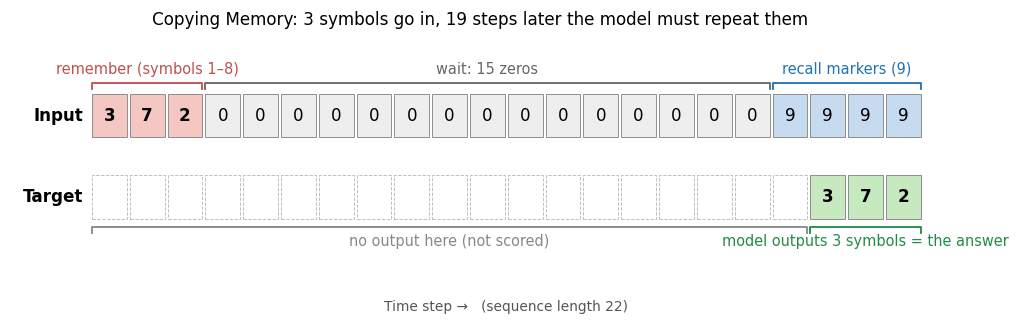

In [ ]:
# All 8^3 = 512 ordered triples of the symbols 1..8: shape [512, 3]
triples = torch.cartesian_prod(*[torch.arange(1, 9)] * MEMORY_K)

# Group the triples by (sum of symbols) mod 8. One group is held out for validation
# and another for test, so those triples never appear during training.
group = (triples - 1).sum(dim=1) % 8
# 384 triples for training, 64 for validation, 64 for test
triple_pools = {'train': triples[group >= 2],
                'val':   triples[group == 0],
                'test':  triples[group == 1]}

def make_memory_dataset(n, pool, seed):
    """Build n sequences [symbols | 0 x (DELAY-1) | 9 x (K+1)] and their targets."""
    g = torch.Generator().manual_seed(seed)
    # Use every triple equally often
    picks = pool[torch.arange(n) % len(pool)]
    # Shuffle their order
    picks = picks[torch.randperm(n, generator=g)]
    # 0 = wait
    waits = torch.zeros(n, DELAY - 1, dtype=torch.long)
    # 9 = recall marker
    recall = torch.full((n, MEMORY_K + 1), 9, dtype=torch.long)
    # Glue the three parts together: [n, 22]
    x = torch.cat([picks, waits, recall], dim=1)
    # Classes 0..7 for cross-entropy
    y = picks - 1
    return TensorDataset(x, y)

memory_sets = {'train': make_memory_dataset(MEMORY_TRAIN, triple_pools['train'], seed=10),
               'val':   make_memory_dataset(MEMORY_VAL,   triple_pools['val'],   seed=11),
               'test':  make_memory_dataset(MEMORY_TEST,  triple_pools['test'],  seed=12)}

print('Distinct triples per split:', {s: len(p) for s, p in triple_pools.items()})

## 8. CNN on Copying Memory
### 8.1 Build the CNN
For sequences we use a 1-D convolution that slides along time. It is **causal**: the output at step *t* only sees steps ≤ *t*. Watch its **receptive field**, the number of past steps each output can see.

In [ ]:
class CausalConv(nn.Module):
    """1-D convolution that only looks at the current and PAST time steps."""
    def __init__(self, width, kernel_size=3, dilation=1):
        super().__init__()
        # Pad (kernel_size - 1) * dilation zeros on the LEFT only, so the output at step t
        # depends on steps t, t-1, ... but never on t+1 (that would be peeking at the future).
        self.left_pad = (kernel_size - 1) * dilation
        # kernel_size=3: each output combines 3 time steps.
        # dilation: the spacing between those 3 steps. dilation=1 -> steps t-2, t-1, t;
        #   dilation=4 -> steps t-8, t-4, t. Larger dilations see further back at the same cost.
        # width channels in and out, so layers can be stacked.
        self.conv = nn.Conv1d(width, width, kernel_size=kernel_size, dilation=dilation)

    def forward(self, x):
        # Input x: [B, width, L] -> output of the same shape
        return F.relu(self.conv(F.pad(x, (self.left_pad, 0))))


class MemoryCNN(nn.Module):
    """Embedding -> causal convolution(s) -> classifier at the 3 recall steps."""
    def __init__(self, dilations=(1,)):
        super().__init__()
        # Embedding: each of the 10 token values (0-9) gets a learned 16-d vector.
        #   num_embeddings must equal the vocabulary size (10); 16 dims is plenty for 10 tokens.
        self.embedding = nn.Embedding(num_embeddings=10, embedding_dim=16)
        # One causal conv layer by default, so the receptive field is only 3 steps. Each recall
        #   step comes 19 steps after the symbol it must output, so this model CANNOT see the
        #   answer. Every extra kernel-3 layer adds 2 steps of view; a dilated layer adds
        #   2 x dilation steps (see the bonus section).
        self.convs = nn.Sequential(*[CausalConv(16, dilation=d) for d in dilations])
        # 16 features -> 8 scores (symbols 1-8) at each position
        self.classifier = nn.Linear(16, 8)

    def forward(self, x):
        # Input x: [B, 22] token ids -> embeddings [B, 22, 16] -> [B, 16, 22] (Conv1d wants channels first)
        h = self.embedding(x).transpose(1, 2)
        # Convolve, then back to [B, 22, 16]
        h = self.convs(h).transpose(1, 2)
        # Predict only at the last 3 positions (the recall steps) -> [B, 3, 8]
        return self.classifier(h[:, -MEMORY_K:])


# Quick check on a fake batch of 2 sequences: output shape and model size.
model = MemoryCNN()
print('output:', tuple(model(torch.zeros(2, SEQ_LEN, dtype=torch.long)).shape),
      '| parameters:', f'{count_params(model):,}')

### 8.2 Train the CNN
**Predict:** can this CNN solve the task if we train it long enough?

In [ ]:
# About 1 s
train_model('Memory', 'CNN', MemoryCNN, memory_sets, epochs=MEMORY_EPOCHS)

### 8.3 CNN results
Stuck at chance (12.5%). At the recall steps its 3-step window contains only `0`s and `9`s, which are identical for every sequence, so it gives the **same answer every time**.

In [ ]:
show_results('Memory', 'CNN')

## 9. RNN (GRU) on Copying Memory
### 9.1 Build the RNN
The GRU reads all 22 steps and must carry the 3 symbols in its memory through the waiting period.

In [ ]:
class MemoryGRU(nn.Module):
    """Embedding -> GRU that carries a memory across all 22 steps -> classifier at the recall steps."""
    def __init__(self):
        super().__init__()
        # 32-d token embeddings: more than enough for 10 token values. The size mainly affects
        #   the GRU's input weights (3 gates x 64 x 32).
        self.embedding = nn.Embedding(10, 32)
        # hidden_size=64: the memory must hold 3 symbols (3 bits each) through 16 waiting steps.
        #   A smaller memory forgets more easily; a larger one costs about hidden_size^2 more.
        self.gru = nn.GRU(input_size=32, hidden_size=64, batch_first=True)
        # Update-gate bias = 1. PyTorch's GRU computes h_new = (1 - z) * candidate + z * h_old,
        #   and bias_ih_l0 stores the reset, update, and candidate biases in that order, so
        #   [64:128] is the update gate z. With bias 1, z starts around sigmoid(1) ≈ 0.73: the GRU
        #   keeps ~73% of its old memory per step instead of ~50%, which helps information
        #   (and gradients) survive the long wait.
        nn.init.constant_(self.gru.bias_ih_l0[64:128], 1.0)
        self.classifier = nn.Linear(64, 8)

    def forward(self, x):
        # Input x: [B, 22]. Output h: [B, 22, 64], the memory state after every step.
        h, _ = self.gru(self.embedding(x))
        # Read the memory at the 3 recall steps -> [B, 3, 8]
        return self.classifier(h[:, -MEMORY_K:])


# Quick check on a fake batch of 2 sequences: output shape and model size.
model = MemoryGRU()
print('output:', tuple(model(torch.zeros(2, SEQ_LEN, dtype=torch.long)).shape),
      '| parameters:', f'{count_params(model):,}')

### 9.2 Train the RNN
**Predict:** can a memory of 64 numbers carry 3 symbols across 16 steps?

In [ ]:
# About 3 s on an Apple M4 Pro
train_model('Memory', 'RNN (GRU)', MemoryGRU, memory_sets, epochs=MEMORY_EPOCHS)

### 9.3 RNN results
Far above chance, but not perfect: it sometimes swaps or repeats symbols. Squeezing 3 symbols through 16 steps of a small memory is hard.

In [ ]:
show_results('Memory', 'RNN (GRU)')

## 10. Transformer on Copying Memory
### 10.1 Build the Transformer
Instead of carrying the symbols forward, each recall step can **attend directly** back to steps 0–2. A causal mask hides future steps.

In [ ]:
class MemoryTransformer(nn.Module):
    """Embedding + positions -> 2 causal attention layers -> classifier at the recall steps."""
    def __init__(self, width=48, layers=2):
        super().__init__()
        self.embedding = nn.Embedding(10, width)
        # Position embedding is essential here: the three recall tokens are all "9", so only
        #   their positions tell output #1 from #2 and #3 (try removing it in the exercises).
        self.position = nn.Parameter(torch.randn(1, SEQ_LEN, width) * 0.02)
        # width=48 (4 heads of 12 dims) and layers=2: small, but enough for this rule. The
        #   model doesn't have to carry symbols step by step like the GRU, so a longer delay
        #   mainly raises the cost (attention grows with SEQ_LEN^2). The attention maps in
        #   10.3 show what the two layers learn.
        self.encoder = transformer_encoder(width, layers)
        self.classifier = nn.Linear(width, 8)
        # Causal mask: True = "may NOT attend". The upper triangle blocks every position from
        #   seeing later ones, the same rule the causal CNN and the GRU follow.
        mask = torch.triu(torch.ones(SEQ_LEN, SEQ_LEN, dtype=torch.bool), diagonal=1)
        # A buffer moves to the GPU with the model but is not a trainable parameter
        self.register_buffer('causal_mask', mask)

    def forward(self, x):
        # Input x: [B, 22] -> token + position embeddings [B, 22, 48]
        h = self.embedding(x) + self.position
        # Each step attends to itself and all earlier steps
        h = self.encoder(h, mask=self.causal_mask)
        # -> [B, 3, 8]
        return self.classifier(h[:, -MEMORY_K:])


# Quick check on a fake batch of 2 sequences: output shape and model size.
model = MemoryTransformer()
print('output:', tuple(model(torch.zeros(2, SEQ_LEN, dtype=torch.long)).shape),
      '| parameters:', f'{count_params(model):,}')

### 10.2 Train the Transformer
**Predict:** will it learn faster or slower than the GRU?

In [ ]:
# About 3 s on an Apple M4 Pro
train_model('Memory', 'Transformer', MemoryTransformer, memory_sets, epochs=MEMORY_EPOCHS)

### 10.3 Transformer results

In [ ]:
show_results('Memory', 'Transformer')

**Where does it look?** Each row is one recall step; darker = more attention. In the last layer, output #1 looks mainly at step 0, #2 at step 1, and #3 at step 2. Attention fetches each symbol directly instead of carrying it through 16 waiting steps.

In [ ]:
# Re-run the trained Transformer layer by layer on 64 test sequences and ask each
# attention module for its weights (which the normal forward pass doesn't return).
transformer = TRAINED[('Memory', 'Transformer')].eval()
mx = memory_sets['test'].tensors[0]
with torch.no_grad():
    # [64, 22, 48]
    h = transformer.embedding(mx[:64]) + transformer.position
    attention_maps = []
    for layer in transformer.encoder.layers:
        # Normalize first, exactly as the pre-norm layer does internally
        z = layer.norm1(h)
        # weights: [64, 22, 22], averaged over the attention heads
        _, weights = layer.self_attn(z, z, z, attn_mask=transformer.causal_mask,
                                     need_weights=True)
        # Keep the 3 recall rows, averaged over the 64 sequences
        attention_maps.append(weights.mean(dim=0)[-MEMORY_K:])
        # Continue to the next layer
        h = layer(h, src_mask=transformer.causal_mask)

fig, axes = plt.subplots(1, len(attention_maps), figsize=(12, 2.3))
for i, (ax, attn) in enumerate(zip(axes, attention_maps)):
    image = ax.imshow(attn, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set(title=f'Layer {i + 1}', xticks=range(SEQ_LEN), yticks=range(MEMORY_K),
           yticklabels=[f'output #{k + 1}' for k in range(MEMORY_K)] if i == 0 else [])
    ax.set_xlabel('Input time step (0–2 = the symbols)')
    ax.tick_params(axis='x', labelsize=7)
fig.colorbar(image, ax=list(axes), label='attention weight', pad=0.01)
plt.show()

## 11. Copying Memory: accuracy and efficiency side by side
Dotted line: chance level (12.5%).

In [ ]:
compare_models('Memory')

### What we learned on Copying Memory
1. **Architecture can set a hard limit.** The local CNN stays at chance: no amount of training helps if the information never reaches the output.
2. **Memory vs. attention.** The RNN carries the symbols step by step and makes mistakes along the way; the Transformer looks back at them directly and learns fastest.
3. **Short sequences make attention cheap.** At only 22 steps, compare the Transformer's and the RNN's time per epoch. Section 12 shows what happens when sequences get long.

*Caveats for both experiments: one seed, few epochs, models of different sizes. Use this for intuition, not as a benchmark.*

## 12. Efficiency at scale: what happens with long inputs?
Attention compares **every token with every other token**, so its cost grows with $L^2$. A CNN's window is fixed (cost ∝ $L$). An RNN is also ∝ $L$, but runs its steps one after another.

We time one training step at lengths 128 → 2,048 (random data; only the cost matters).

In [ ]:
# Same width for all three, so only the architecture differs. Batch 16 keeps the
# Transformer's memory manageable at L=2048 (about 5 GB on an M4 Pro).
WIDTH, SWEEP_BATCH = 64, 16
LENGTHS = [128, 256, 512, 1024, 2048] if device.type != 'cpu' else [128, 256, 512, 1024]

class SeqCNN(nn.Module):
    """4 stacked causal convolutions (receptive field 9 steps)."""
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(10, WIDTH)
        self.convs = nn.Sequential(*[CausalConv(WIDTH) for _ in range(4)])
        self.head = nn.Linear(WIDTH, 8)
    def forward(self, x):
        # Input x: [B, L] -> conv features [B, D, L]
        h = self.convs(self.embedding(x).transpose(1, 2))
        # -> [B, L, 8]
        return self.head(h.transpose(1, 2))

class SeqGRU(nn.Module):
    """1 GRU layer."""
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(10, WIDTH)
        self.gru = nn.GRU(WIDTH, WIDTH, batch_first=True)
        self.head = nn.Linear(WIDTH, 8)
    def forward(self, x):
        # -> [B, L, 8]
        return self.head(self.gru(self.embedding(x))[0])

class SeqTransformer(nn.Module):
    """4 Transformer blocks."""
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(10, WIDTH)
        self.encoder = transformer_encoder(WIDTH, layers=4)
        self.head = nn.Linear(WIDTH, 8)
    def forward(self, x):
        # -> [B, L, 8]
        return self.head(self.encoder(self.embedding(x)))

def measure(Model, length, steps=3):
    """Return (milliseconds per training step, MB of activations for one batch)."""
    model = Model().to(device)
    optimizer = torch.optim.AdamW(model.parameters())
    x = torch.randint(0, 10, (SWEEP_BATCH, length), device=device)
    y = torch.randint(0, 8, (SWEEP_BATCH, length), device=device)

    def train_step():
        optimizer.zero_grad()
        F.cross_entropy(model(x).reshape(-1, 8), y.reshape(-1)).backward()
        optimizer.step()

    # One warm-up step (not timed)
    train_step()
    synchronize()
    start = time.perf_counter()
    for _ in range(steps):
        train_step()
    synchronize()
    ms = (time.perf_counter() - start) / steps * 1000
    return ms, activation_memory_mb(model, x)

SWEEP_MODELS = {'CNN': SeqCNN, 'RNN (GRU)': SeqGRU, 'Transformer': SeqTransformer}
sweep = []
for L in LENGTHS:
    for name, Model in SWEEP_MODELS.items():
        seed_everything()
        try:
            ms, mb = measure(Model, L)
        except RuntimeError as err:
            # Out of GPU memory -> leave a gap instead of crashing
            if 'out of memory' not in str(err).lower():
                raise
            ms, mb = float('nan'), float('nan')
            print(f'L={L}: {name} ran out of memory')
        free_gpu_cache()
        sweep.append(dict(model=name, length=L, ms_per_step=ms, activation_mb=mb))
    print(f'L={L:5d} done')
scaling = pd.DataFrame(sweep)

# Time per step (ms): one row per length, one column per model.
display(scaling.pivot(index='length', columns='model', values='ms_per_step')
        [list(SWEEP_MODELS)].round(1))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for name in SWEEP_MODELS:
    curve = scaling[scaling.model == name]
    axes[0].plot(curve.length, curve.ms_per_step, marker='o', color=palette[name], label=name)
    axes[1].plot(curve.length, curve.activation_mb, marker='o', color=palette[name], label=name)

# Gray guide lines: perfect "∝ L" (linear) and "∝ L²" (quadratic) growth,
# drawn through the last RNN point and the last Transformer point.
L = np.array(LENGTHS, dtype=float)
for ax, column in zip(axes, ['ms_per_step', 'activation_mb']):
    end = scaling[scaling.length == LENGTHS[-1]].set_index('model')[column]
    if np.isfinite(end['Transformer']):
        ax.plot(L, end['Transformer'] * (L / L[-1]) ** 2, ls='--', color='gray', lw=1, label='∝ L²')
    if np.isfinite(end['RNN (GRU)']):
        ax.plot(L, end['RNN (GRU)'] * (L / L[-1]), ls=':', color='gray', lw=1, label='∝ L')
    ax.set(xscale='log', xlabel='Sequence length L')
    ax.set_xticks(LENGTHS, [str(n) for n in LENGTHS])
    # Hide the cluttered log-scale minor ticks on the x axis
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.legend(fontsize=8)
axes[0].set(title='Time per training step', ylabel='Milliseconds')
axes[1].set(title='GPU memory for activations', ylabel='MB')
fig.tight_layout()
fig.savefig(RESULT_DIR / 'scaling.png', bbox_inches='tight')
plt.show()

# How much does each model's step time grow when the length doubles? (2× = linear, 4× = quadratic)
times = scaling.pivot(index='length', columns='model', values='ms_per_step')
growth = times.loc[LENGTHS[-1]] / times.loc[LENGTHS[-2]]
print(f'Doubling L from {LENGTHS[-2]} to {LENGTHS[-1]} multiplies step time by: '
      + ', '.join(f'{m} {growth[m]:.1f}×' for m in SWEEP_MODELS))
last = scaling[scaling.length == LENGTHS[-1]].set_index('model')
print(f'At L={LENGTHS[-1]}, a Transformer step takes '
      f'{last.ms_per_step["Transformer"] / last.ms_per_step["CNN"]:.0f}× as long as a CNN step', end='')
if device.type != 'cpu':
    print(f' and needs {last.activation_mb["Transformer"] / last.activation_mb["CNN"]:.0f}× the memory', end='')
print('.')

**Takeaway:** the Transformer's curves bend upward and follow the $L^2$ line (dashed): doubling the length roughly quadruples its time and memory, and its memory dwarfs the others. The y axis is linear here, so a curve that climbs faster and faster is growing worse than linearly. The RNN grows only ∝ $L$ but is slow at every length because its steps can't run in parallel. The CNN barely notices longer inputs. (On NVIDIA GPUs, PyTorch may use FlashAttention-style kernels that cut attention's memory, but not its $L^2$ compute.)

## 13. Bonus: give the CNN a wider view
The CNN failed the recall task because its window was too small, not because CNNs can't do sequences. **Dilated** convolutions (gaps 1, 2, 4, 8) see $1 + 2(1+2+4+8) = 31$ steps, more than the whole 22-step input.

In [ ]:
def receptive_field(dilations, kernel_size=3):
    """How many input steps one output can see through a stack of causal convolutions."""
    return 1 + (kernel_size - 1) * sum(dilations)

print('Local CNN sees', receptive_field([1]), 'steps | dilated CNN sees',
      receptive_field([1, 2, 4, 8]), 'steps | sequence length:', SEQ_LEN)
# Same MemoryCNN class, just four dilated layers instead of one plain layer
train_model('Memory', 'Dilated CNN', lambda: MemoryCNN(dilations=(1, 2, 4, 8)),
            memory_sets, epochs=MEMORY_EPOCHS)
show_results('Memory', 'Dilated CNN')

## 14. Save and reload a model
Save the `state_dict` (the weights), not the Python object. To reload, rebuild the architecture and load the weights into it.

In [ ]:
cnn = TRAINED[('MNIST', 'CNN')]
checkpoint = RESULT_DIR / 'mnist_cnn_state.pt'
# Weights only: a dict of tensors
torch.save(cnn.state_dict(), checkpoint)

# Same architecture, fresh random weights
reloaded = ImageCNN()
reloaded.load_state_dict(torch.load(checkpoint, weights_only=True))
cnn.eval(); reloaded.eval()

# Same input -> same output proves the weights were restored.
x = image_sets['test'].tensors[0][:16]
with torch.no_grad():
    assert torch.allclose(cnn(x), reloaded(x), atol=1e-6)
print('Reloaded model gives identical outputs.')

# Keep the numbers for later analysis.
pd.DataFrame(RESULTS.values()).to_csv(RESULT_DIR / 'results.csv', index=False)
pd.DataFrame([h for hs in HISTORIES.values() for h in hs]).to_csv(RESULT_DIR / 'learning_curves.csv', index=False)
scaling.to_csv(RESULT_DIR / 'scaling.csv', index=False)
print('Saved to', RESULT_DIR)

## 15. Try it yourself
Predict first, change **one** hyperparameter, then rerun that model's build, train, and results cells.

| Question | Change | Watch |
|---|---|---|
| Bigger CNN filters? | `kernel_size=5, padding=2` in both `ImageCNN` convs | MFLOPs, accuracy, time |
| A bigger RNN memory? | `hidden_size=128` in `ImageGRU` (and `nn.Linear(128, 10)`) | Parameters, accuracy, time |
| Finer Transformer patches? | Train `lambda: ImageTransformer(patch=2)` | Time, memory, accuracy |
| Does depth widen a CNN's view? | Train `lambda: MemoryCNN(dilations=(1,) * 10)` | Recall accuracy |
| Does attention need positions? | Delete `+ self.position` in `MemoryTransformer.forward` | Recall accuracy |
| Learning rate too high? | `LEARNING_RATE = 1e-2` (rerun from the top) | Learning curves |

**Further reading:** [PyTorch basics](https://docs.pytorch.org/tutorials/beginner/basics/) · [Vision Transformer paper](https://arxiv.org/abs/2010.11929) · [Copying Memory task](https://github.com/locuslab/TCN/tree/master/TCN/copy_memory)